In [43]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-selection"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

In [2]:
path = Path("/exp/sbnd/data/users/syebes/LambdaAnalysis/michelTagging")
root_file = "output.root"

In [3]:
file = uproot.open(path / root_file)

In [4]:
file.keys()

['ana;1', 'ana/subrunTree;1', 'ana/tree;1']

In [5]:
tree = file['ana/tree']

In [6]:
tree.keys()

['file_name',
 'event_id',
 'run_id',
 'subrun_id',
 'gen_index',
 'nu_pdg',
 'nu_e0',
 'nu_weight',
 'nu_int_mode',
 'nu_int_type',
 'nu_cc_nc',
 'nu_target',
 'nu_hit_nuc',
 'nu_hit_quark',
 'nu_w',
 'nu_x',
 'nu_y',
 'nu_q_sqr',
 'gen_id',
 'gen_status_code',
 'gen_mother',
 'gen_pdg',
 'gen_mass',
 'gen_e0',
 'gen_start_x',
 'gen_start_y',
 'gen_start_z',
 'gen_p0_x',
 'gen_p0_y',
 'gen_p0_z',
 'g4_id',
 'g4_mother',
 'g4_pdg',
 'g4_mass',
 'g4_e0',
 'g4_ef',
 'g4_tl',
 'g4_start_x',
 'g4_start_y',
 'g4_start_z',
 'g4_start_wire_u',
 'g4_start_wire_v',
 'g4_start_wire_c',
 'g4_start_time_tick',
 'g4_start_channel_u',
 'g4_start_channel_v',
 'g4_start_channel_c',
 'g4_end_x',
 'g4_end_y',
 'g4_end_z',
 'g4_end_wire_u',
 'g4_end_wire_v',
 'g4_end_wire_c',
 'g4_end_time_tick',
 'g4_end_channel_u',
 'g4_end_channel_v',
 'g4_end_channel_c',
 'g4_p0_x',
 'g4_p0_y',
 'g4_p0_z',
 'g4_pf_x',
 'g4_pf_y',
 'g4_pf_z',
 'g4_process',
 'g4_end_process',
 'event_n_slices',
 'slc_filled',
 'slc_id

In [8]:
slices = tree.arrays(tree.keys(), library='ak')

In [18]:
evt_mask = (slices.event_id == 42) & (slices.subrun_id == 345)

lambda_mask = (slices.nu_pdg == -14) & (slices.nu_cc_nc == 0)

In [20]:
slc = slices[evt_mask & lambda_mask]

In [21]:
slc.slc_pfp_true_pdg

<Array [[-1, -13]] type='1 * var * int32'>

In [75]:
hits = slc[['slc_hits_wireID',
 'slc_hits_plane_id',
 'slc_hits_tpc_id',
 'slc_hits_channel_id',
 'slc_hits_peaktime',
'slc_hits_true_id',
           'slc_hits_pfp_id',]]

In [76]:
hits[h_mask].slc_hits_true_id

<Array [[20250410, 20250408, ..., 20000073, 20000073]] type='1 * var * int32'>

In [77]:
slc.g4_pdg

<Array [[-11, 12, -14, 22, ..., -211, 3122, -13, 22]] type='1 * var * int32'>

In [78]:
slc.g4_id

<Array [[10002387, 10002386, ..., 10000002, 10000001]] type='1 * var * int32'>

In [79]:
slc.slc_hits_true_id[:, :, None]

<Array [[[20250410], [20250408], ..., [20000096]]] type='1 * var * 1 * int32'>

In [80]:
slc.g4_id[:, None, :]

<Array [[[10002387, 10002386, ..., 10000001]]] type='1 * 1 * var * int32'>

In [81]:
g4_id = slc.g4_id[0]
g4_pdg = slc.g4_pdg[0]
hit_id = slc.slc_hits_true_id[0]

mapping = dict(zip(ak.to_list(g4_id), ak.to_list(g4_pdg)))
hit_pdg = ak.Array([mapping.get(i, -1) for i in ak.to_list(hit_id)])

In [82]:
mapping

{10002387: -11,
 10002386: 12,
 10002385: -14,
 10002227: 22,
 10002225: 11,
 10002224: -12,
 10002221: 22,
 10002220: 22,
 10002219: 22,
 10002218: 22,
 10002217: 22,
 10002190: 2212,
 10002189: 2212,
 10002173: 1000180400,
 10002171: 1000180400,
 10002169: 1000180400,
 10002168: 1000180400,
 10002167: 1000180400,
 10002166: 1000180400,
 10002165: 1000180400,
 10002163: 1000180400,
 10002162: 1000180400,
 10002161: 1000180400,
 10002160: 1000180400,
 10002159: 1000180400,
 10002158: 1000180400,
 10002157: 1000180400,
 10002153: 1000180360,
 10002152: 1000180400,
 10002151: 1000180400,
 10002150: 1000180400,
 10002149: 1000180400,
 10002146: 1000180400,
 10002145: 1000180400,
 10002144: 1000180400,
 10002143: 1000180400,
 10002142: 1000180400,
 10002141: 1000180400,
 10002139: 1000180400,
 10002138: 1000180400,
 10002137: 1000180400,
 10002136: 1000180400,
 10002132: 1000180400,
 10002131: 1000180400,
 10002130: 1000180360,
 10002047: 22,
 10002046: 22,
 10002045: 22,
 10002044: 22,
 1

In [83]:
hit_id

<Array [20250410, 20250408, ..., 20000096, 20000096] type='901 * int32'>

In [94]:
max(hits.slc_hits_pfp_id[0])

8

In [106]:
slc.slc_pfp_id

<Array [[90, 8]] type='1 * var * int32'>

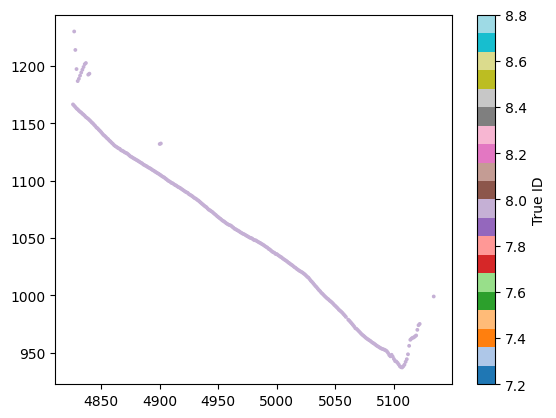

In [97]:
h_mask = (hits.slc_hits_plane_id == 2) & (hits.slc_hits_pfp_id >= 0)

plt.scatter(
    hits[h_mask].slc_hits_channel_id,
    hits[h_mask].slc_hits_peaktime,
    s=3,
    c=hits[h_mask].slc_hits_pfp_id,
    cmap="tab20",   # o "viridis", "Set3", etc.
)

plt.colorbar(label="True ID")